# Q5 — improve the saved small U-Net without retraining

**Names / NetIDs:** [fill before submission]

The original `unet_submission.csv` received **public S = 0.34684**, as shown in the user's screenshot. The target is **S = 0.65**. S combines segmentation PQ and matching F1; it is not classification accuracy. The latest request narrows work to existing U-Net weights. Alternative-model training was stopped; its partial artifacts are not selected here. No Kaggle upload is performed.


In [1]:
from pathlib import Path
import json,hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tifffile,cv2
from skimage.segmentation import mark_boundaries
from cell_matching import read_pair,normalize,decode_rle,summarize

from cell_alignment import match_prediction
from advanced_cells import write_submission

out=Path('outputs/q5/advanced')
rows=pd.read_csv('Data/training/train_ground_truth.csv')
public=json.loads((out/'public_baseline.json').read_text())
choice=json.loads((out/'selected.json').read_text())
print('Previous public score:',public['score'],'target:',public['target'])
print('Selected deployment:',choice)

Previous public score: 0.34684 target: 0.65
Selected deployment: {'method': 'context128_tta', 'deform': False, 'structure': 1, 'gate': 8, 'cutoff': 0.25, 'pq_invivo': 0.5994634245936613, 'pq_exvivo': 0.3628183871400455, 'f1_match': 0.3016710642040457, 'score': 0.39140598503544954, 'segmentation': {'invivo': 'context128_tta', 'exvivo': 'context128_tta'}}


## 1. Reuse existing weights; improve inference

Load unchanged modality checkpoints from `outputs/q5/unet_complete/`. Compare 128-pixel tiles (matching the original training context), 50% tile overlap with center-weighted blending, and rotation averaging over four right-angle rotations. Compare 256-pixel tiles with the same averaging. Preserve the original percentile normalization of 16-bit TIFFs and the model's calibrated watershed and area parameters. No neural training occurs.

Sources: L5 p.111 and L6 p.70 (modality normalization and mask diagnostics); the scalar rotation averaging and tile weighting are new adaptations. Registration builds on L3 similarity/RANSAC and L5 codelab cells25–27; no label-assisted transform is used at inference. Optional CPD follows [Coherent Point Drift](https://arxiv.org/abs/0905.2635), implemented with `pycpd==2.0.0`.

To repeat the released-data benchmark: `.venv/bin/python run_cell_experiments.py`, then `.venv/bin/python cell_alignment.py`. Existing prediction masks are reused when present. Core dependencies plus `requirements-unet.txt` and `requirements-unet-improved.txt` suffice for this selected pipeline; Cellpose and StarDist dependencies are not used.


In [2]:
segmentation=pd.read_csv(out/'unet_inference_comparison.csv')
assert all(count==47 for count in segmentation.groupby(['method','modality']).size())
table=segmentation.groupby(['method','modality']).pq.mean().unstack()
display(table.round(4))


modality,exvivo,invivo
method,,
context128,0.3544,0.5832
context128_tta,0.3628,0.5995
context256_tta,0.3600,0.5821


## 2. Matching and retrospective validation

Each region's segmentation uses the existing checkpoint trained without that mouse. Evaluate strict IoU >0.75, region-averaged modality PQ and pooled matching F1 with the locally reconstructed metric; the official scorer is unavailable. All mice were inspected previously, so this is retrospective development validation, not an untouched test estimate.

Compare centroid-triangle and image-correlation affine hypotheses, guarded mutual-neighbor ICP, overlap-aware confidence, Hungarian assignment with unmatched options, optional neighborhood-distance cost and optional smooth CPD refinement using mutual local anchors. Test gates4/6/8, confidence thresholds0.15/0.25, structural cost0/1 and CPD off/on. Prediction code uses no ground-truth matches or per-test-ID settings.

For the grouped selection below, pick settings on the other two mice, then evaluate the excluded mouse's saved-weight predictions. This remains retrospective and is not a fully nested training procedure. Deployment settings use all released training regions. The hybrid option selects the modality's inference variant on other mice during validation and on all released data for deployment.


In [3]:
comparison=pd.read_csv(out/'matching_summary.csv')
display(comparison.head(12).round(4))
grouped=json.loads((out/'grouped_summary.json').read_text())
previous=json.loads(Path('outputs/q5/unet_complete/validation_summary.json').read_text())
selected=pd.read_csv(out/'selected_per_region.csv')
display(pd.DataFrame({'Previous small U-Net':previous,'Improved grouped selection':grouped,'Selected configuration':summarize(selected)}).T.round(4))
display(pd.read_csv(out/'selected_per_mouse.csv').round(4))
recoverable=selected.recoverable_pairs.sum();verified=selected.verified_pairs.sum()
summary=summarize(selected)
ceiling=.25*(summary['pq_invivo']+summary['pq_exvivo'])+.5*(2*recoverable/(recoverable+verified))
print('Correct/predicted/verified:',selected[['correct_pairs','predicted_pairs','verified_pairs']].sum().to_dict())
print('Mask-recoverable pairs:',int(recoverable),'fixed-mask oracle S:',round(ceiling,4))
print('Selected sources per excluded mouse:')
display(selected.groupby(selected.sample_id.str.split('__').str[0])[['source_invivo','source_exvivo']].first())

,method,deform,structure,gate,cutoff,pq_invivo,pq_exvivo,f1_match,score
0,context128_tta,False,1,8,0.25,0.5995,0.3628,0.3017,0.3914
1,context128_tta,False,1,6,0.25,0.5995,0.3628,0.3010,0.3911
2,context128_tta,True,1,8,0.25,0.5995,0.3628,0.3008,0.3910
3,context128_tta,True,1,6,0.25,0.5995,0.3628,0.2995,0.3903
4,context128_tta,True,0,6,0.25,0.5995,0.3628,0.2993,0.3902
5,context128_tta,False,0,6,0.25,0.5995,0.3628,0.2991,0.3901
6,context128_tta,False,0,8,0.25,0.5995,0.3628,0.2973,0.3892
7,context128_tta,True,0,8,0.25,0.5995,0.3628,0.2966,0.3889
8,context128_tta,True,0,4,0.25,0.5995,0.3628,0.2953,0.3882
9,hybrid,False,1,8,0.25,0.5995,0.3551,0.2980,0.3876


,pq_invivo,pq_exvivo,f1_match,score
Previous small U-Net,0.5602,0.3475,0.2840,0.3689
Improved grouped selection,0.5971,0.3517,0.2762,0.3753
Selected configuration,0.5995,0.3628,0.3017,0.3914


,mouse,pq_invivo,pq_exvivo,f1_match,score
0,subject_5d294c,0.5191,0.3440,0.3357,0.3836
1,subject_b2ba5e,0.5996,0.3004,0.1611,0.3055
2,subject_db6b8b,0.6708,0.4246,0.3364,0.4420


Correct/predicted/verified: {'correct_pairs': 343, 'predicted_pairs': 1135, 'verified_pairs': 1139}
Mask-recoverable pairs: 560 fixed-mask oracle S: 0.5702
Selected sources per excluded mouse:


,source_invivo,source_exvivo
sample_id,,
subject_5d294c,context128_tta,context128_tta
subject_b2ba5e,context128_tta,context128_tta
subject_db6b8b,context128_tta,context128_tta


## 3. Inspect native predictions

Show the first dataset region, using its excluded-mouse predictions and selected fold sources. Ground truth determines display crops only; prediction code does not load training annotations at test time. Also show strongest/weakest predicted alignment support as diagnostics, selected without hidden labels.

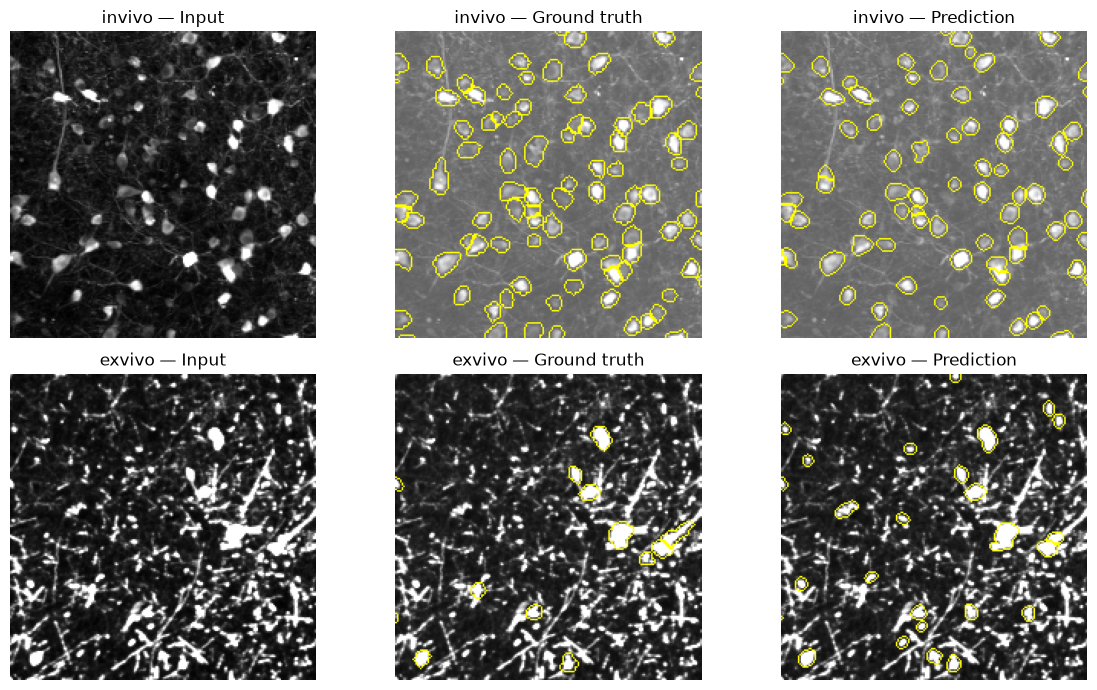

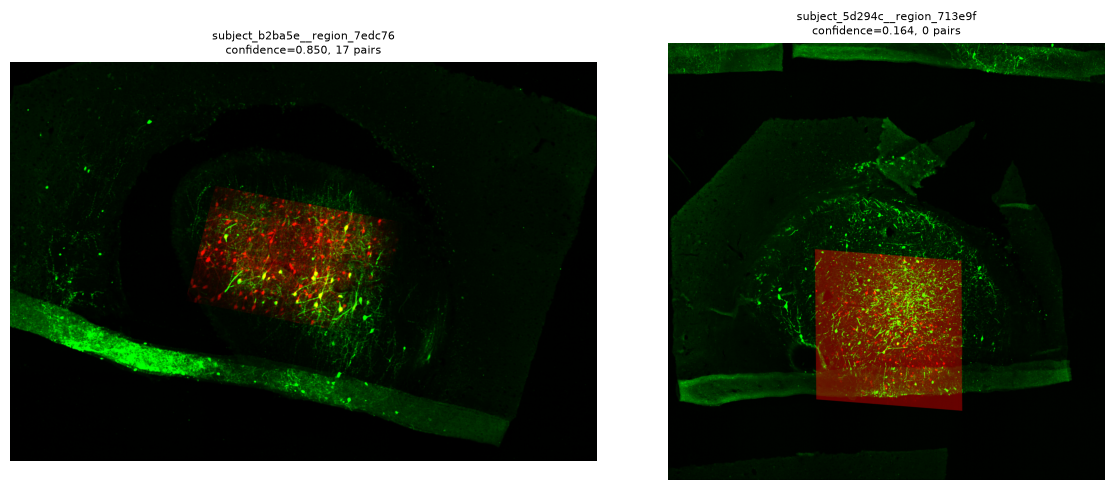

In [4]:
example=rows.iloc[0];result=selected.set_index('sample_id').loc[example.sample_id]
images=read_pair('Data/training',example.sample_id)
labels=[tifffile.imread(out/'masks'/result['source_'+m]/example.sample_id/f'{m}.tif') for m in ['invivo','exvivo']]
fig,axes=plt.subplots(2,3,figsize=(12,7))
for image,mask,modality,panels in zip(images,labels,['invivo','exvivo'],axes):
    truth=np.zeros(image.shape,np.int32)
    for i,rle in enumerate(json.loads(example[modality+'_instances']).values(),1):truth[decode_rle(rle,image.shape)]=i
    y,x=np.argwhere(truth>0).mean(0).astype(int)
    y,x=max(0,min(y-100,image.shape[0]-200)),max(0,min(x-100,image.shape[1]-200));crop=np.s_[y:y+200,x:x+200]
    for panel,view,title in zip(panels,[normalize(image)[crop],mark_boundaries(normalize(image)[crop],truth[crop]),mark_boundaries(normalize(image)[crop],mask[crop])],['Input','Ground truth','Prediction']):
        panel.imshow(view,cmap='gray');panel.set(title=modality+' — '+title);panel.axis('off')
plt.tight_layout();plt.savefig(out/'predictions.png',dpi=150);plt.show()
settings={key:choice[key] for key in ['gate','cutoff','deform','structure']}
fig,axes=plt.subplots(1,2,figsize=(12,5))
for panel,index in zip(axes,[selected.confidence.idxmax(),selected.confidence.idxmin()]):
    record=selected.loc[index];pair_images=read_pair('Data/training',record.sample_id)
    masks=[tifffile.imread(out/'masks'/record['source_'+m]/record.sample_id/f'{m}.tif') for m in ['invivo','exvivo']]
    pairs,matrix,statistics=match_prediction(pair_images,masks,**settings)
    if matrix is not None:
        warped=cv2.warpAffine(normalize(pair_images[0]),matrix,(pair_images[1].shape[1],pair_images[1].shape[0]))
        panel.imshow(np.stack([warped,normalize(pair_images[1]),np.zeros_like(warped)],-1))
    panel.set_title(f'{record.sample_id}\nconfidence={statistics["confidence"]:.3f}, {len(pairs)} pairs',fontsize=8);panel.axis('off')
plt.tight_layout();plt.savefig(out/'alignments.png',dpi=150);plt.show()

## 4. Final candidate and reproduction

Load the unchanged all-training U-Net checkpoints and selected inference/matching settings; generate every supplied hidden-test row automatically. The inference pipeline never loads training labels or fits model weights. Native masks, diagnostics and the selected configuration are saved under `outputs/q5/advanced/`.

Reproduce from the saved checkpoints with:

```bash
.venv/bin/python advanced_cells.py --output "Kaggle Submissions/unet_improved.csv"
```

The original submission is preserved. A local improvement does not establish a new Kaggle public score or guarantee the0.65 target. Use the measured comparison above to assess the result.

The notebook reuses prepared test masks only when the recorded inference variants match the selected settings and all native TIFFs exist. The command above regenerates predictions from checkpoints.


In [5]:
submission=write_submission(reuse_masks=True)
counts=pd.DataFrame({'invivo':submission.invivo_instances.map(lambda s:len(json.loads(s))),'exvivo':submission.exvivo_instances.map(lambda s:len(json.loads(s))),'pairs':submission.match_pairs.map(lambda s:len(json.loads(s)))})
print('Rows:',len(submission),'totals:',counts.sum().to_dict(),'zero-pair regions:',int((counts.pairs==0).sum()))
print('CSV SHA-256:',hashlib.sha256(Path('Kaggle Submissions/unet_improved.csv').read_bytes()).hexdigest())
display(submission[['sample_id']].join(counts).head())

MATCHED subject_78b6a7__region_33daed 29 {'confidence': 0.3123339796504789, 'support': 20.301708677281127, 'close': 24}


MATCHED subject_78b6a7__region_64dd4d 16 {'confidence': 0.2754269938706652, 'support': 11.843360736438603, 'close': 13}


MATCHED subject_78b6a7__region_7754ed 0 {'confidence': 0.242242199395674, 'support': 12.1121099697837, 'close': 14}


MATCHED subject_78b6a7__region_798993 0 {'confidence': 0.20468112524558113, 'support': 14.737041017681841, 'close': 15}


MATCHED subject_78b6a7__region_7c48e3 0 {'confidence': 0.24863628405667515, 'support': 14.172268191230483, 'close': 14}


...

MATCHED subject_d7a97c__region_d472db 0 {'confidence': 0.18954973009750894, 'support': 14.784878947605698, 'close': 14}


MATCHED subject_d7a97c__region_dd13e1 19 {'confidence': 0.4671756629635015, 'support': 12.14656723705104, 'close': 13}


MATCHED subject_d7a97c__region_f24078 0 {'confidence': 0.17733653940728678, 'support': 15.782952007248523, 'close': 16}


Rows: 29 totals: {'invivo': 8954, 'exvivo': 4176, 'pairs': 384} zero-pair regions: 16
CSV SHA-256: 9e1a0beab6dd285c04e84090a5fe3b9e31d80f4120f8773502162eed7bc24327


,sample_id,invivo,exvivo,pairs
0,subject_78b6a7__region_33daed,385,181,29
1,subject_78b6a7__region_64dd4d,273,102,16
2,subject_78b6a7__region_7754ed,346,106,0
3,subject_78b6a7__region_798993,395,129,0
4,subject_78b6a7__region_7c48e3,368,139,0


## 5. Preservation and AI disclosure

OpenAI Codex assisted with implementation, experiments and validation. The actual user prompts, including the narrowing request29, are recorded in `AI_USAGE.md`. Source data, previous notebooks, previous U-Net checkpoints and CSVs, Q1–Q4 and README are preserved. No external upload or final-submission selection occurs. Alternative-model experiments were interrupted and have partial results only.


In [6]:
for name,expected in json.loads((out/'preserved_hashes.json').read_text()).items():
    assert hashlib.sha256(Path(name).read_bytes()).hexdigest()==expected,name
print('Earlier notebooks, source helpers, model checkpoints, CSVs and README are unchanged.')

Earlier notebooks, source helpers, model checkpoints, CSVs and README are unchanged.


## Measured outcome and limits

The saved-weight pipeline increased retrospective grouped S from **0.3689 to0.3753**. Selecting one fixed configuration using all released regions gives **S=0.3914**, with PQ **0.5995 /0.3628** and pooled matching F1 **0.3017**; this selected score is optimistic relative to grouped setting selection. Deployment uses128-pixel tiles,50% overlap, weighted blending, four-rotation averaging, structural Hungarian matching with gate8 and confidence0.25. CPD was tested and not selected.

The29-row candidate contains8,954 in-vivo masks,4,176 ex-vivo masks and384 pairs;16 regions have no predicted pairs. Prior candidate:9,329 /4,130 masks,229 pairs and23 zero-pair regions. Extra pairs alone do not establish correctness. Visual diagnostics still show ex-vivo false positives/boundary errors and weak alignment.

Only560 of1,139 verified training pairs are recoverable under the improved masks and strict IoU threshold. Perfect matching of those pairs would cap local S at approximately **0.5702**. The0.65 target is unmet; no new Kaggle score is known. Improving matching alone cannot close the full gap for these masks. No additional neural training was performed after request29.
